# Demo of diffusion-based FWI on Marmousi model (step3)

## Description
This notebook implements DMFWI using Deepwave and PyTorch.  
It is designed for generating synthetic seismic data, performing wave propagation simulation, and updating velocity models through gradient-based optimization.

## Workflow
1. Import required libraries
2. Load velocity model and acquisition parameters
3. Generate source wavelets and geometry
4. Run forward simulation
5. Compute loss between observed and simulated data
6. Update model parameters
7. Visualize results

## Author
Chao Li

## Date
2026-04-07

In [1]:
import time
import torch
from torchvision import transforms as T, utils
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import io
import hydra
from omegaconf import DictConfig
import os
import sys
import deepwave
from deepwave import scalar
from torch.optim import Adam
from torchaudio.functional import biquad
from scipy.ndimage import gaussian_filter
from scipy.signal import butter
from torch import optim
import sys
from utils.utils import *
from diffusionreg import myprediff
from denoising_diffusion_pytorch.denoising_diffusion_pytorch_only import num_to_groups, Trainer, Unet, GaussianDiffusion
from hydra import initialize, compose
from omegaconf import DictConfig

/home/lcgeo/anaconda3/envs/lcgeopy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dx        = 25                 # step interval along x/z direction
dt        = 0.003                # time interval (e.g., 3ms)
num_dims  = 2                     # dimension of velocity model
nz        = 141                  # model shape of z dimension (depth) Marmousi2
ny        = 681                   # model shape of y dimension Marmousi2
vmodel_dim = np.array([nz, ny])

total_t   = 6                      # totle sampling time (unit: s)
nt        = int(total_t / dt)       # number of time sampling points
num_shots = 65                  # nunmber of shots
num_sources_per_shot = 1            # number of sources per shot
num_receivers_per_shot = 680        # number of receivers per shot


source_spacing=10 ###this is the number of grid not the real distance 6:dx*6=150m
receiver_spacing=1 ###this is the number of grid not the real distance 1=25m

source_depth = 0                # the index depth of sources, default is 0
receiver_depth = 0              # the index depths of receivers, default is 0
order          = 8              # precision order of finite difference in space domain

fwi_lr            = 2       # learning rate for updating the model.
fwi_batch         = 65      # number of batches for FWI.
fwi_num_epochs    = 20       # number of FWI iteration test
survey_pad = None
savepoch = 50                 # Saving models each 50 FWI iterations
first_source=0
n_sources_per_shot=1
first_receiver=0

diffreg=1                     ####whther use diffusion regularization
nwater=19                     #### thickness of water layer

Text(0.5, 1.0, 'Initial')

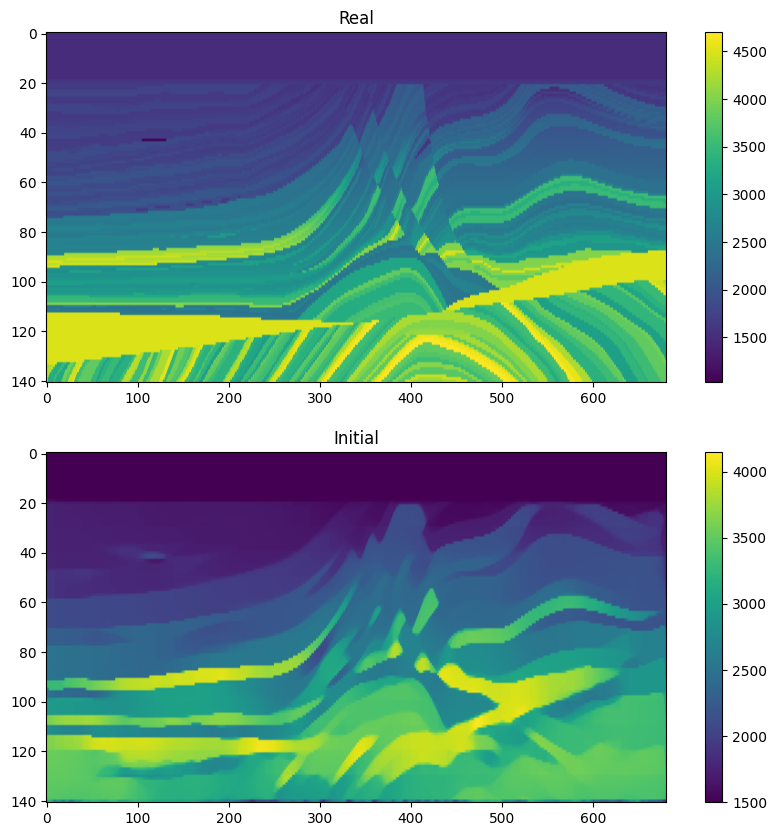

In [3]:
torch.backends.cudnn.enabled = True     ######activate CUDNN
torch.backends.cudnn.benchmark = True   ######select the optimal optimization method

cuda_available = torch.cuda.is_available()
device = torch.device("cuda:0" if cuda_available else "cpu")

directadd=os.path.join(os.getcwd())


data_path = directadd+'/data_marmall/vel_marm_281_1361.bin'
initsafile = directadd+'/data_marmall/mar_big_initsource.mat'
initfile = directadd+'/results/Marmnpy/dfwimarm_step2.npy'

fwi_resultnpy = directadd+'/results/Marmnpy/'


# Loading the true model
model_true = loadtruemodel(data_path, num_dims, vmodel_dim).to(device)


model= np.load(initfile)
model[0:nwater,:]=1500

model_init = model

model = torch.tensor(model_init).float().to(device) 

model.requires_grad = True 
model = torch.nn.Parameter(model)

plt.figure(figsize=(10,10))
plt.subplot(2,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Real")
plt.subplot(2,1,2)
plt.imshow(model.detach().cpu().numpy(),aspect='auto')
plt.colorbar()
plt.title("Initial")



Text(0.5, 1.0, 'Observed shots')

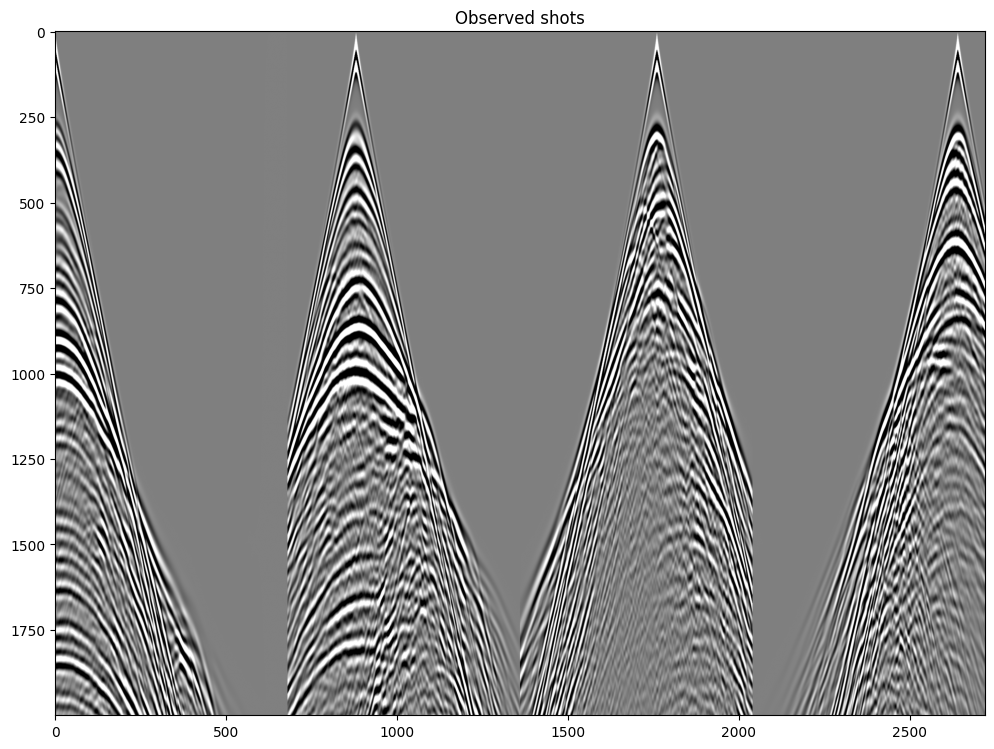

In [4]:
# Creating source and reciver locations

source_locations = torch.zeros(
            num_shots, n_sources_per_shot, 2, dtype=torch.long, device=device
        )
source_locations[..., 1] = source_depth

source_locations[:, 0, 0] = torch.arange(num_shots) * source_spacing + first_source



receiver_locations = torch.zeros(
            num_shots, num_receivers_per_shot, 2, dtype=torch.long, device=device
        )
receiver_locations[..., 1] = receiver_depth
receiver_locations[:, :, 0] = (
            (torch.arange(num_receivers_per_shot) * receiver_spacing + first_receiver).repeat(num_shots, 1)
        )

source_amplitudes_init, source_amplitudes_true = loadinitsource(initsafile,device)
source = source_amplitudes_init.repeat(1,num_shots, num_sources_per_shot).permute(1,0,2).permute(0,2,1)


out = deepwave.scalar(model_true.T, dx, dt, source_amplitudes=source,
             source_locations=source_locations,
             receiver_locations=receiver_locations,
             accuracy=8,         
             pml_width=[10,10,0,10])

rcv_amps_true = out[-1].permute(2,0,1)

plt.figure(figsize=(12,10))
plt.imshow(rcv_amps_true[:,::20,:].detach().cpu().numpy().reshape(rcv_amps_true[:,::20,:].shape[0],rcv_amps_true[:,::20,:].shape[1]*rcv_amps_true[:,::20,:].shape[2]),cmap='gray',vmin=-1,vmax=1)
plt.title('Observed shots')

In [5]:
############function for diffusion regularization
def myreg(tmodel,ws1,ws2,tartime):
    with initialize(config_path="config",version_base=None):
         cfg = compose(config_name="config")
         
    modelr = myprediff(cfg, tmodel,ws1,ws2,tartime)
   
    return modelr


from torchsummary import summary

### optimizer for the velocity model
optimizer = optim.Adam([{'params': model, 'lr':fwi_lr, 'betas':(0.5, 0.9), 'eps':1e-8, 'weight_decay':0}])  #####The model here is initial model

SNR = 0.0
SSIM = 0.0
Loss = 0.0
ERROR = 0.0

#######################step 6

import torch.nn.functional as F

t_start = time.time()

# number of shots per batch
num_shots_per_batch = int(num_shots / fwi_batch)  #####30/30

for i in range(fwi_num_epochs):
    # initialization of the loss
    epoch_loss = 0.0

    for it in range(fwi_batch):
    
        iteration = i*fwi_batch+it+1
        # Set both optimizers to zero grad.
        optimizer.zero_grad()
     
        batch_src_amps = source_amplitudes_init.repeat(1, num_shots_per_batch, 1).permute(1,0,2).permute(0,2,1)

        batch_rcv_amps_true = rcv_amps_true[:,it::fwi_batch].to(device)
        

        
        batch_x_s = source_locations[it::fwi_batch].to(device)
        batch_x_r = receiver_locations[it::fwi_batch].to(device)

        

        outpre = deepwave.scalar(model.T, dx, dt, source_amplitudes=batch_src_amps,
             source_locations=batch_x_s,
             receiver_locations=batch_x_r,
             accuracy=8,         
             pml_width=[10,10,0,10])

        batch_rcv_amps_pred = outpre[-1].permute(2,0,1)
            
        d_real = (batch_rcv_amps_true).permute(1,0,2)
  
        
        
        d_real = d_real.unsqueeze(1)
        
              
              
        d_fake = (batch_rcv_amps_pred).permute(1,0,2)
    
        d_fake = d_fake.unsqueeze(1)
        

               
        
        loss =   F.pairwise_distance(d_fake, d_real, keepdim = True).mean()  
        
      
       
        epoch_loss += loss.item()
        loss.backward()
     
        
        # Clips gradient value of model
        torch.nn.utils.clip_grad_value_(model,1e3) 
        
       

        model.grad[0:nwater,:]=0 
        # Update the velocity model
        optimizer.step()
        # clip the model value that keep the minimum value is larger than 0
    
        
        model.data=torch.clamp(model.data,min=950,max=4700)
   
    ########add diffusion regularization here
    if i==fwi_num_epochs-1 and diffreg==1:
         ws1=10
         ws2=10
         tartime=100
         model=myreg(model,ws1,ws2,100).clone()
         model.requires_grad = True 

    
    Loss = np.append(Loss, epoch_loss / fwi_batch)

    # compute the SNR and SSIM
    snr = ComputeSNR(model.detach().cpu().numpy(),  
              model_true.detach().cpu().numpy())
    SNR = np.append(SNR, snr)

    ssim = ComputeSSIM(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    SSIM = np.append(SSIM, ssim)

    rerror = ComputeRE(model.detach().cpu().numpy(), \
              model_true.detach().cpu().numpy())
    ERROR = np.append(ERROR, rerror)

    print('Epoch:', i+1, 'Loss: ', epoch_loss / fwi_batch, 'SNR:', snr, 'SSIM:', ssim.cpu().detach().cpu().numpy())

                          
                        

# Estimating the FWI time
t_end = time.time()
elapsed_time = t_end - t_start
print('Running complete in {:.0f}m  {:.0f}s' .format(elapsed_time //60 , elapsed_time % 60))


Epoch: 1 Loss:  9.160307847536528 SNR: 15.91568 SSIM: 0.43941262
Epoch: 2 Loss:  7.157957392472487 SNR: 15.913179 SSIM: 0.47670648
Epoch: 3 Loss:  6.229240531187791 SNR: 15.907707 SSIM: 0.49211258
Epoch: 4 Loss:  5.780954177563007 SNR: 15.904261 SSIM: 0.5000263
Epoch: 5 Loss:  5.539205382420467 SNR: 15.903748 SSIM: 0.50513315
Epoch: 6 Loss:  5.387296042075524 SNR: 15.905718 SSIM: 0.5089122
Epoch: 7 Loss:  5.274993034509512 SNR: 15.909637 SSIM: 0.5119798
Epoch: 8 Loss:  5.1823883735216585 SNR: 15.914951 SSIM: 0.51461136
Epoch: 9 Loss:  5.1003360436512875 SNR: 15.921223 SSIM: 0.5169584
Epoch: 10 Loss:  5.023966369262109 SNR: 15.928083 SSIM: 0.51908517
Epoch: 11 Loss:  4.950132650595445 SNR: 15.935439 SSIM: 0.5210408
Epoch: 12 Loss:  4.876904738866366 SNR: 15.943154 SSIM: 0.52288365
Epoch: 13 Loss:  4.803775990926303 SNR: 15.951168 SSIM: 0.524617
Epoch: 14 Loss:  4.732127450062678 SNR: 15.959438 SSIM: 0.52626514
Epoch: 15 Loss:  4.663184859202459 SNR: 15.968042 SSIM: 0.5278475
Epoch: 16 L

sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 301.25it/s]


1


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1822.52it/s]


2


...

358


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1825.25it/s]


359


sampling loop time step L0: 100%|██████████| 100/100 [00:00<00:00, 1820.42it/s]


Epoch: 20 Loss:  4.334696982457087 SNR: 15.975845 SSIM: 0.3840851
Running complete in 1m  58s


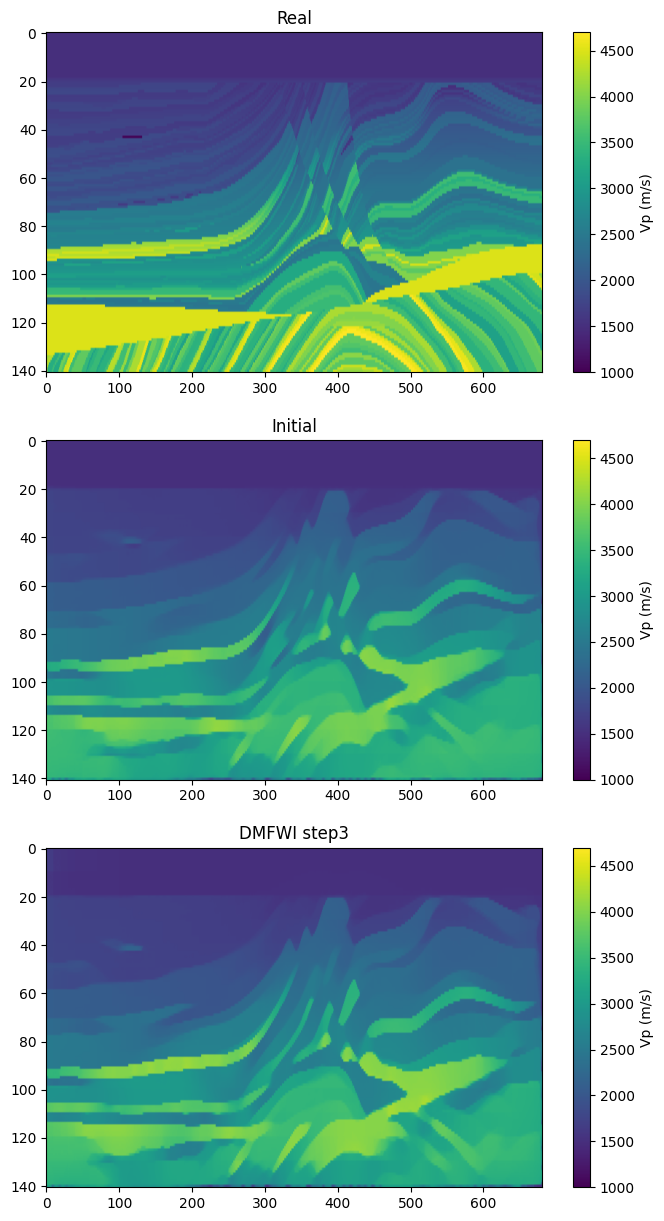

In [6]:
plt.figure(figsize=(8,15))
plt.subplot(3,1,1)
plt.imshow(model_true.detach().cpu().numpy(),aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("Real")
plt.subplot(3,1,2)
plt.imshow(model_init,aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("Initial")
plt.subplot(3,1,3)
plt.imshow(model.detach().cpu().numpy(),aspect='auto',vmin=1000,vmax=4700)
plt.colorbar(label="Vp (m/s)")
plt.title("DMFWI step3")

outnpy='dfwimarm_step3.npy'

np.save(fwi_resultnpy+ outnpy, model.cpu().data.numpy())      # save for step4